# RT-DETR Colab: Denoising Tuning

У цьому експерименті ми досліджували вплив
кількості denoising queries на навчання RT-DETR-L. На відміну від baseline, ми зменшили параметр
num_denoising зі 100 до 50, залишивши
learning rate = 0.001 та інші основні
налаштування незмінними.

Denoising queries використовуються під час навчання
як допоміжні запити із зашумленими мітками
та координатами об'єктів. Модель навчається
відновлювати правильні передбачення, що
допомагає оптимізувати процес детекції.

Ми перевіряли, чи дозволить зменшення кількості
таких запитів покращити якість навчання
за обмеженої кількості епох. При цьому кількість основних object queries,
які використовуються для детекції, залишалася
незмінною (300).

Для порівняння з baseline використовували
ті самі 3 folds, 6 епох навчання та однакові
підвибірки кадрів.

## 0. Середовище, файли та відтворюваність

In [1]:
!pip -q install -U kaggle
import os
from pathlib import Path
from google.colab import files, userdata

key_file = Path('/root/.kaggle/kaggle.json')
if key_file.exists():
    print('Kaggle API credentials already available')
else:
    try:
        token = userdata.get('KAGGLE_API_TOKEN')
    except Exception:
        token = None
    if token:
        os.environ['KAGGLE_API_TOKEN'] = token
        print('Kaggle API token взято з Colab Secrets')
    else:
        print('Відкрий Colab Secrets і додай KAGGLE_API_TOKEN, або завантаж свій kaggle.json')
        files.upload()

Відкрий Colab Secrets і додай KAGGLE_API_TOKEN, або завантаж свій kaggle.json


Saving kaggle.json to kaggle.json


In [2]:
# Підготовка авторизації для Kaggle CLI: сучасний token або kaggle.json.
from pathlib import Path
import os
kaggle_dir = Path('/root/.kaggle')
kaggle_dir.mkdir(exist_ok=True)
if Path('/content/kaggle.json').exists():
    os.replace('/content/kaggle.json', str(kaggle_dir / 'kaggle.json'))
credentials = kaggle_dir / 'kaggle.json'
if credentials.exists():
    os.chmod(credentials, 0o600)
else:
    assert os.environ.get('KAGGLE_API_TOKEN'), 'Не знайдено API token або kaggle.json'
print('Kaggle authentication configured')

Kaggle authentication configured


In [ ]:
# Завантаження competition data
from pathlib import Path
DATA_DIR = Path('/content/competition')
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / 'train' / 'annotations_coco.json').is_file():
    !kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/competition
else:
    print('Competition data вже розпаковані; повторно не завантажуємо')

100% 9.88G/9.88G [09:00<00:00, 19.6MB/s]



In [ ]:
import zipfile
from pathlib import Path
root = Path('/content/competition')
if not (root / 'train' / 'annotations_coco.json').is_file():
    zip_files = list(root.glob('*.zip'))
    assert zip_files, 'ZIP-архів не знайдено — перевір команду download'
    for zip_path in zip_files:
        print('Розпаковуємо:', zip_path.name)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(root)
assert (root / 'train' / 'annotations_coco.json').is_file(), 'Train annotations не знайдено після розпакування'
print('Train і val готові:', (root / 'val' / 'annotations_coco.json').is_file())

Розпаковуємо: multiple-object-video-detection-hw-2-ucu-ai-2026.zip
Train і val готові: True


In [5]:
from pathlib import Path

root = Path("/content/competition")

candidates = [
    p.parent.parent
    for p in root.rglob("annotations_coco.json")
    if p.parent.name == "train"
]

print("Знайдені папки:", candidates)

if len(candidates) == 1:
    DATA_ROOT = candidates[0]
    print("DATA_ROOT:", DATA_ROOT)
    print("Train exists:", (DATA_ROOT / "train").exists())
    print("Val exists:", (DATA_ROOT / "val").exists())

Знайдені папки: [PosixPath('/content/competition')]
DATA_ROOT: /content/competition
Train exists: True
Val exists: True


In [ ]:
import os, sys, json, time, random, shutil, hashlib, subprocess, importlib.util
from pathlib import Path

for module, package in [("ultralytics", "ultralytics"), ("pycocotools", "pycocotools"), ("yaml", "pyyaml")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import torch, numpy as np, pandas as pd, yaml, ultralytics
from PIL import Image
from ultralytics import RTDETR
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Увімкніть GPU перед навчанням."
SEED=42
FOLDS=[0, 1, 2]
TRAIN_STEP=5
VAL_STEP=2
EPOCHS=6
BATCH_SIZE=2
IMG_SIZE=640
NUM_WORKERS=2
AMP=True
PATIENCE=100
EVAL_CONF=0.05
EVAL_BATCH=4
PRETRAINED_WEIGHTS_OVERRIDE=None
COMPETITION_SLUG='multiple-object-video-detection-hw-2-ucu-ai-2026'
NAMES=['person','bicycle','car','van','truck','tricycle','bus','motor']
USE_FAST_EVAL=False

print('Ultralytics:', ultralytics.__version__, 'Torch:',torch.__version__)
print('GPU:',torch.cuda.get_device_name(0))

Ultralytics: 8.4.203 Torch: 2.14.1+cu130
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_BASE=Path('/content/')
PREP_ROOT=DRIVE_BASE/'preprocessed'      # train.json, val.json, folds.json
DATA_ROOT=Path('/content/competition')
if not (DATA_ROOT/'train'/'annotations_coco.json').exists():
    DATA_ROOT=DRIVE_BASE/'original_dataset'
RUN_ROOT=DRIVE_BASE/'rtdetr_cv'
CACHE_ROOT=Path('/content/rtdetr_fold_data')
RUN_ROOT.mkdir(parents=True,exist_ok=True);CACHE_ROOT.mkdir(parents=True,exist_ok=True)
assert all((PREP_ROOT/f).exists() for f in ('train.json','val.json','folds.json')), ('Поклади 3 preprocessing файли у '+str(PREP_ROOT))
assert (DATA_ROOT/'train'/'annotations_coco.json').exists(), ('Не знайдені оригінальні зображення: '+str(DATA_ROOT))
print('Original images:', DATA_ROOT, '\nPreprocessed:', PREP_ROOT, '\nOutputs in Drive:', RUN_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original images: /content/competition 
Preprocessed: /content/preprocessed 
Outputs in Drive: /content/rtdetr_cv


## 1. Відтворюємо GroupKFold + sequence-level subsampling
Оригінальні image IDs, GT boxes та ignored regions беремо з preprocessing. Конвертація IDs класів 1–8 → 0–7 потрібна лише для Ultralytics YOLO labels. Файли YOLO labels формуються для кожного fold; symlinks на оригінальні images економлять місце.

In [ ]:
from collections import defaultdict

with (PREP_ROOT/'train.json').open() as f: TRAIN_RECORDS=json.load(f)
with (PREP_ROOT/'folds.json').open() as f: FOLD_MAP=json.load(f)
with (DATA_ROOT/'train'/'annotations_coco.json').open() as f: SOURCE_COCO=json.load(f)
META={int(x['id']):x for x in SOURCE_COCO['images']}
assert len(TRAIN_RECORDS)==len(FOLD_MAP)==24201, 'Потрібні повні preprocessing files з FRAME_STEP=1.'
assert set(int(x) for x in FOLD_MAP.values())=={0,1,2}

def seq_name(rec):
    return Path(str(rec['file_name']).replace('\\','/')).parent.name

def sample_by_sequence(records, step):
    seqs=defaultdict(list)
    for rec in records: seqs[seq_name(rec)].append(rec)
    return [rec for key in sorted(seqs) for rec in sorted(seqs[key],key=lambda x:x['file_name'])[::step]]

TRAIN_POOL=sample_by_sequence(TRAIN_RECORDS, TRAIN_STEP)
VAL_POOL=sample_by_sequence(TRAIN_RECORDS, VAL_STEP)

def fold_records(fold):
    tr=[r for r in TRAIN_POOL if int(FOLD_MAP[r['file_name']])!=fold]
    va=[r for r in VAL_POOL if int(FOLD_MAP[r['file_name']])==fold]
    assert tr and va
    assert {seq_name(r) for r in tr}.isdisjoint({seq_name(r) for r in va})
    assert {r['file_name'] for r in tr}.isdisjoint({r['file_name'] for r in va})
    return tr,va

for f in (0,1,2):
    tr,va=fold_records(f)
    print(f'Fold {f}: {len(tr):,} train / {len(va):,} OOF val, disjoint sequences OK')
print('Training pool:',len(TRAIN_POOL),'| OOF validation pool:',len(VAL_POOL))
object_counts=np.array([len(r['boxes']) for r in VAL_POOL])
print('Scene density on OOF validation: max=',object_counts.max(),
      '| median=',float(np.median(object_counts)),
      '| >300 objects=',int((object_counts>300).sum()),
      ' / ',len(object_counts))
print('Pretrained RT-DETR decoder uses 300 object queries; dense scenes may hit a recall ceiling.')

# У Faster R-CNN IDs: 1..8 (+0 background). У Ultralytics YOLO: 0..7.
def label_lines(rec):
    meta=META[int(rec['image_id'])]
    w,h=int(meta['width']),int(meta['height'])
    rows=[]
    assert len(rec['boxes'])==len(rec['labels'])
    for box, old_label in zip(rec['boxes'],rec['labels']):
        cid=int(old_label)-1
        assert 0<=cid<8, (rec['file_name'],cid)
        x1,y1,x2,y2=map(float,box)
        if not (x2>x1 and y2>y1): continue
        xc=((x1+x2)/2)/w; yc=((y1+y2)/2)/h
        bw=(x2-x1)/w; bh=(y2-y1)/h
        vals=[max(0.0,min(1.0,z)) for z in (xc,yc,bw,bh)]
        if vals[2] and vals[3]: rows.append(str(cid)+' '+' '.join(f'{v:.7f}' for v in vals))
    return rows

def _output_relative_filename(filename):
    """Remove the original COCO `images/` prefix before creating YOLO folders."""
    rel=Path(str(filename).replace('\\','/'))
    assert not rel.is_absolute() and '..' not in rel.parts, f'Unsafe image file name: {filename}'
    if rel.parts and rel.parts[0]=='images':
        rel=Path(*rel.parts[1:])
    assert rel.parts and 'images' not in rel.parts, f'Unexpected nested images/ directory: {filename}'
    return rel


def build_yolo_fold(fold):
    """Create standard YOLO image-label pairs. Rebuild automatically if layout is old."""
    from ultralytics.data.utils import img2label_paths

    root=CACHE_ROOT/f'fold_{fold}'
    tr,va=fold_records(fold)
    yaml_path=root/'data.yaml'
    marker=root/'.layout_v2_complete.json'
    settings={
        'layout_version':2,
        'fold':int(fold),
        'train_step':int(TRAIN_STEP),
        'val_step':int(VAL_STEP),
        'data_root':str(DATA_ROOT.resolve()),
        'folds_hash':hashlib.sha256((PREP_ROOT/'folds.json').read_bytes()).hexdigest(),
    }
    if marker.is_file() and yaml_path.is_file():
        try:
            if json.loads(marker.read_text())==settings:
                print(f'Fold {fold}: reusing verified YOLO dataset at {root}')
                return yaml_path
        except (ValueError, OSError):
            pass

    # Old layout contains images/train/images/... but labels/train/images/...
    # Ultralytics replaces the LAST /images/ component, so NONE of those labels are found.
    # Only remove temporary converted data, never original data or saved model checkpoints.
    if root.exists():
        shutil.rmtree(root)
    for split,records in [('train',tr),('val',va)]:
        nonempty=0
        for rec in tqdm(records,desc=f'YOLO labels {fold}/{split}',leave=False):
            original_rel=Path(str(rec['file_name']).replace('\\','/'))
            relative=_output_relative_filename(rec['file_name'])
            source=DATA_ROOT/'train'/original_rel
            assert source.is_file(),f'Missing source image: {source}'
            dest=root/'images'/split/relative
            dest.parent.mkdir(parents=True,exist_ok=True)
            dest.symlink_to(source.resolve())
            label=root/'labels'/split/relative.with_suffix('.txt')
            label.parent.mkdir(parents=True,exist_ok=True)
            lines=label_lines(rec)
            label.write_text('\n'.join(lines),encoding='utf-8')
            nonempty+=bool(lines)
            expected_label=Path(img2label_paths([str(dest)])[0])
            assert expected_label==label, (
                f'Ultralytics expects {expected_label}, but created {label}'
            )
        assert nonempty>0, f'Fold {fold}/{split} contains no nonempty annotation files'
        print(f'Fold {fold}/{split}: {len(records)} images, {nonempty} images with objects')
    config={'path':str(root.resolve()),'train':'images/train','val':'images/val',
            'nc':8,'names':dict(enumerate(NAMES))}
    yaml_path.write_text(yaml.safe_dump(config,sort_keys=False),encoding='utf8')
    marker.write_text(json.dumps(settings,indent=2),encoding='utf-8')
    return yaml_path

test_rec=TRAIN_POOL[0]
print('First record:',test_rec['file_name'],'| first YOLO labels:',label_lines(test_rec)[:2])

Fold 0: 3,243 train / 4,044 OOF val, disjoint sequences OK
Fold 1: 3,243 train / 4,046 OOF val, disjoint sequences OK
Fold 2: 3,250 train / 4,024 OOF val, disjoint sequences OK
Training pool: 4868 | OOF validation pool: 12114
Scene density on OOF validation: max= 161 | median= 43.0 | >300 objects= 0  /  12114
Pretrained RT-DETR decoder uses 300 object queries; dense scenes may hit a recall ceiling.
First record: images/uav0000013_00000_v/0000001.jpg | first YOLO labels: ['0 0.3284970 0.7764550 0.0260417 0.1164021', '0 0.3229167 0.7572751 0.0267857 0.1124339']


## 2. Навчання RT-DETR
Свіжий pretrained checkpoint для кожного fold. Кожен fold створює `best.pt`, `last.pt` і `results.csv` (mAP на validation після кожної епохи). Налаштування експерименту фіксуємо в config.json.

In [ ]:
EXPERIMENT='denoising'
print("Variant:",EXPERIMENT)

Variant: denoising


In [ ]:
from pathlib import Path
import gc

# Tuning ONLY is enabled via the model-specific trainer class for Colab.
CUSTOM_DENOISING=None
if EXPERIMENT=='denoising':
    from ultralytics.models.rtdetr.train import RTDETRTrainer
    class CustomDenoisingTrainer(RTDETRTrainer):
        def get_model(self, cfg=None, weights=None, verbose=True):
            model=super().get_model(cfg,weights,verbose)
            head=model.model[-1]
            assert hasattr(head,'num_denoising') and hasattr(head,'label_noise_ratio'), 'Ultralytics RTDETRDecoder API changed'
            print('Denoising BEFORE:', head.num_denoising,head.label_noise_ratio,head.box_noise_scale)
            head.num_denoising=50
            print('Denoising AFTER:',head.num_denoising,head.label_noise_ratio,head.box_noise_scale)
            return model
    CUSTOM_DENOISING=CustomDenoisingTrainer

LR = {'baseline':0.001, 'lr_tuning':0.0003,'denoising':0.001}[EXPERIMENT]
RUN_NAME={'baseline':'rtdetr_baseline','lr_tuning':'rtdetr_lr_0003','denoising':'rtdetr_denoising_50'}[EXPERIMENT]
RUN_DIR=RUN_ROOT/RUN_NAME
RUN_DIR.mkdir(parents=True,exist_ok=True)

config={
    'experiment':EXPERIMENT,'run':RUN_NAME,'train_step':TRAIN_STEP,'val_step':VAL_STEP,
    'folds_definition_sha256':hashlib.sha256((PREP_ROOT/'folds.json').read_bytes()).hexdigest(),
    'train_files_sha256':hashlib.sha256(json.dumps([r['file_name'] for r in TRAIN_POOL]).encode()).hexdigest(),
    'val_files_sha256':hashlib.sha256(json.dumps([r['file_name'] for r in VAL_POOL]).encode()).hexdigest(),
    'epochs':EPOCHS,'batch':BATCH_SIZE,'imgsz':IMG_SIZE,'seed':SEED,'lr0':LR,
    'model':'rtdetr-l.pt','num_classes':8,'num_queries':300,
    'denoising_queries':50 if EXPERIMENT=='denoising' else 100,
    'amp':AMP,'optimizer':'AdamW','mosaic':0.0,'mixup':0.0,
    'val_method':'YOLO per epoch; COCO OOF after all training with ignored-crowd approximation',
    'ultralytics_version':ultralytics.__version__,
}
config_path=RUN_DIR/'config.json'
if config_path.is_file():
    old=json.loads(config_path.read_text())
    assert old==config,'RUN_NAME конфліктує з попередньою конфігурацією. Обери нову назву.'
else: config_path.write_text(json.dumps(config,indent=2,ensure_ascii=False))
print('Experiment config:',json.dumps(config,indent=2))


def weights_path():
    if PRETRAINED_WEIGHTS_OVERRIDE is not None:
        path=Path(PRETRAINED_WEIGHTS_OVERRIDE)
        assert path.is_file(),f'Pretrained file missing: {path}'
        return str(path)
    return 'rtdetr-l.pt'


def train_one_fold(fold):
    fold_dir=RUN_DIR/f'fold_{fold}'
    if (fold_dir/'fold_result.json').is_file():
        print(f'Fold {fold}: COCO evaluation completed; skipping training.')
        return
    best_saved=fold_dir/'weights'/'best.pt'
    done_file=fold_dir/'training_done.json'
    results_csv=fold_dir/'results.csv'
    if best_saved.is_file() and done_file.is_file():
        print(f'Fold {fold}: training is complete; only COCO evaluation remains.')
        return
    if best_saved.is_file() and results_csv.is_file():
        historic=pd.read_csv(results_csv)
        if len(historic)>=EPOCHS:
            print(f'Fold {fold}: all {EPOCHS} epochs found in results.csv; do not resume a completed run.')
            return
    yaml_path=build_yolo_fold(fold)
    (fold_dir).mkdir(parents=True,exist_ok=True)
    pretrained=weights_path()
    latest=fold_dir/'weights'/'last.pt'
    if latest.is_file():
        print('Resuming saved fold',fold,'from',latest)
        model=RTDETR(str(latest))
        resume=True
    else:
        model=RTDETR(pretrained)
        resume=False
    print('Starting fold',fold, '| learning rate',LR,'| resume',resume)
    train_args=dict(
        data=str(yaml_path),epochs=EPOCHS,batch=BATCH_SIZE,imgsz=IMG_SIZE,
        device=0,workers=NUM_WORKERS,seed=SEED+fold,deterministic=False,
        project=str(RUN_DIR),name=f'fold_{fold}',exist_ok=True,
        pretrained=True,optimizer='AdamW',lr0=LR,lrf=0.1,
        amp=AMP,patience=PATIENCE,save=True,save_period=-1,plots=False,
        val=True,mosaic=0.0,mixup=0.0,copy_paste=0.0,
        fliplr=0.5,flipud=0.0, degrees=0.0,translate=0.0,scale=0.0,
        cache=False,verbose=True,resume=resume,
    )
    if CUSTOM_DENOISING is not None: train_args['trainer']=CUSTOM_DENOISING
    started=time.perf_counter()
    model.train(**train_args)
    elapsed=time.perf_counter()-started
    # If training done, best is used for COCO evaluation
    best=fold_dir/'weights'/'best.pt'
    last=fold_dir/'weights'/'last.pt'
    assert best.exists() or last.exists(),f'No checkpoint saved for fold {fold}: {fold_dir}'
    (fold_dir/'training_done.json').write_text(json.dumps({
        'fold':fold,'best_weights':str(best if best.exists() else last),
        'last_weights':str(last),'seconds_train_and_native_validation':elapsed,
        'complete':True},indent=2))
    del model
    gc.collect();torch.cuda.empty_cache()
    print('Fold',fold,'TRAINING DONE. Checkpoint:',best if best.exists() else last)

for fold in FOLDS:
    train_one_fold(fold)

Experiment config: {
  "experiment": "denoising",
  "run": "rtdetr_denoising_50",
  "train_step": 5,
  "val_step": 2,
  "folds_definition_sha256": "36e128263142d18ff3b8e321e7f7b379a54e3bc0f1e25dfa2beacf85b67b2713",
  "train_files_sha256": "b0eef6c9dc3673734906c5c95d4b9b3b7e0838564ec603c7ea7619d958cf32d3",
  "val_files_sha256": "fde4a07ff504cec93f9f4ac58fef1a93590e6d029e8ce0a8e3b57d8ac518a733",
  "epochs": 6,
  "batch": 2,
  "imgsz": 640,
  "seed": 42,
  "lr0": 0.001,
  "model": "rtdetr-l.pt",
  "num_classes": 8,
  "num_queries": 300,
  "denoising_queries": 50,
  "amp": true,
  "optimizer": "AdamW",
  "mosaic": 0.0,
  "mixup": 0.0,
  "val_method": "YOLO per epoch; COCO OOF after all training with ignored-crowd approximation",
  "ultralytics_version": "8.4.203"
}


YOLO labels 0/train:   0%|          | 0/3243 [00:00<?, ?it/s]

Fold 0/train: 3243 images, 3243 images with objects


YOLO labels 0/val:   0%|          | 0/4044 [00:00<?, ?it/s]

Fold 0/val: 4044 images, 4042 images with objects
Starting fold 0 | learning rate 0.001 | resume False
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rtdetr_fold_data/fold_0/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-

YOLO labels 1/train:   0%|          | 0/3243 [00:00<?, ?it/s]

... (3 outputs left out)

YOLO labels 2/train:   0%|          | 0/3250 [00:00<?, ?it/s]

Fold 2/train: 3250 images, 3250 images with objects


YOLO labels 2/val:   0%|          | 0/4024 [00:00<?, ?it/s]

Fold 2/val: 4024 images, 4024 images with objects
Starting fold 2 | learning rate 0.001 | resume False
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rtdetr_fold_data/fold_2/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-

## 3. Незалежна COCO-оцінка (OOF)
Усі predictions повертаємо до оригінальних координат. Використовуємо однакові category IDs, COCO maxDets=100 та однакову обробку ignored GT, що в Faster R-CNN. Окремо рахуються inference ms/image і AP_small.

In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import io,contextlib

def xywh(box):
    x1,y1,x2,y2=map(float,box)
    return [x1,y1,max(0.,x2-x1),max(0.,y2-y1)]

def gt_for_fold(records):
    images=[]; anns=[]
    for r in records:
        im=META[int(r['image_id'])]
        images.append({'id':int(r['image_id']),'width':int(im['width']),'height':int(im['height'])})
        for box,cid in zip(r['boxes'],r['labels']):
            b=xywh(box)
            anns.append({'id':len(anns)+1,'image_id':int(r['image_id']),
                         'category_id':int(cid),'bbox':b,'area':b[2]*b[3], 'iscrowd':0})
        for box in r['ignored_boxes']:
            b=xywh(box)
            for cid in range(1,9):
                anns.append({'id':len(anns)+1,'image_id':int(r['image_id']),
                             'category_id':cid,'bbox':b,'area':b[2]*b[3],'iscrowd':1,'ignore':1})
    return {'images':images,'annotations':anns,
            'categories':[{'id':i,'name':NAMES[i-1]} for i in range(1,9)]}

def coco_eval(gt, preds):
    coco=COCO();coco.dataset=gt
    with contextlib.redirect_stdout(io.StringIO()): coco.createIndex()
    if preds:
        with contextlib.redirect_stdout(io.StringIO()): det=coco.loadRes(preds)
    else:
        det=COCO();det.dataset={'images':gt['images'],'annotations':[],'categories':gt['categories']}
        with contextlib.redirect_stdout(io.StringIO()): det.createIndex()
    ev=COCOeval(coco,det,'bbox')
    ev.params.imgIds=[i['id'] for i in gt['images']]
    ev.params.catIds=list(range(1,9))
    with contextlib.redirect_stdout(io.StringIO()): ev.evaluate();ev.accumulate();ev.summarize()
    return {'mAP':float(ev.stats[0]),'AP50':float(ev.stats[1]),'AP_small':float(ev.stats[3]),
            'AP_medium':float(ev.stats[4]),'AP_large':float(ev.stats[5])}

def evaluate_one_fold(fold):
    fold_dir=RUN_DIR/f'fold_{fold}'
    path=fold_dir/'fold_result.json'
    if path.is_file():
        print('COCO evaluation fold',fold,'already exists; skipping.')
        return
    _,records=fold_records(fold)
    weights=fold_dir/'weights'/'best.pt'
    if not weights.exists(): weights=fold_dir/'weights'/'last.pt'
    assert weights.is_file(),'Train this fold before evaluating.'
    model=RTDETR(str(weights))
    preds=[];inference_s=0.;inference_n=0
    for i in tqdm(range(0,len(records),EVAL_BATCH),desc=f'COCO fold {fold}'):
        bunch=records[i:i+EVAL_BATCH]
        paths=[str(DATA_ROOT/'train'/str(r['file_name']).replace('\\','/')) for r in bunch]
        results=model.predict(source=paths,imgsz=IMG_SIZE,device=0,
                              conf=EVAL_CONF,max_det=300,verbose=False,quantize=16 if AMP else 32,
                              stream=False)
        assert len(results)==len(bunch)
        for r,res in zip(bunch,results):
            # r.boxes.cls has IDs 0..7, COCO expects IDs 1..8.
            if res.boxes is None: continue
            if res.speed and 'inference' in res.speed:
                inference_s+=float(res.speed['inference'])/1000.
                inference_n+=1
            for box,cls,score in zip(res.boxes.xyxy.cpu().tolist(),
                                     res.boxes.cls.cpu().tolist(),
                                     res.boxes.conf.cpu().tolist()):
                preds.append({'image_id':int(r['image_id']),
                              'category_id':int(cls)+1,'bbox':xywh(box),'score':float(score)})
    gt=gt_for_fold(records)
    stats=coco_eval(gt,preds)
    stats['ms_per_image']=1000*inference_s/max(inference_n,1)
    stats['frames']=len(records)
    # GT and predictions retained for pooled OOF and failure cases.
    tmp=path.with_suffix('.tmp')
    tmp.write_text(json.dumps({'fold':fold,'metrics':stats,'ground_truth':gt,
                               'predictions':preds,'n_train':len(fold_records(fold)[0]),
                               'n_val':len(records)}))

    tmp.replace(path)

    drive_result = (
        BACKUP / f"fold_{fold}" / "fold_result.json"
    )

    drive_result.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, drive_result)

    assert drive_result.is_file()
    assert drive_result.stat().st_size == path.stat().st_size

    print(f"COCO fold {fold} saved to Google Drive!")

    del model

    gc.collect();torch.cuda.empty_cache()
    print('Fold',fold,stats)

for fold in FOLDS:
    evaluate_one_fold(fold)

COCO fold 0:   0%|          | 0/1011 [00:00<?, ?it/s]

COCO fold 0 saved to Google Drive!
Fold 0 {'mAP': 0.18585054980975857, 'AP50': 0.35360513338115357, 'AP_small': 0.0716116918923913, 'AP_medium': 0.13709146208738185, 'AP_large': 0.27884017722229715, 'ms_per_image': 23.95930498071763, 'frames': 4044}


COCO fold 1:   0%|          | 0/1012 [00:00<?, ?it/s]

COCO fold 1 saved to Google Drive!
Fold 1 {'mAP': 0.1217430049326374, 'AP50': 0.22786963243223846, 'AP_small': 0.029784234967429643, 'AP_medium': 0.10910225252735661, 'AP_large': 0.3078597522616815, 'ms_per_image': 24.224203713059147, 'frames': 4046}


COCO fold 2:   0%|          | 0/1006 [00:00<?, ?it/s]

COCO fold 2 saved to Google Drive!
Fold 2 {'mAP': 0.12542593363979723, 'AP50': 0.246572266086241, 'AP_small': 0.038253178382130666, 'AP_medium': 0.12698258970873044, 'AP_large': 0.27231100566920907, 'ms_per_image': 24.466218217201813, 'frames': 4024}


## 4. Підсумкова 3-fold OOF таблиця
Підсумкова pooled OOF mAP — це одна COCOeval на всіх out-of-fold predictions.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

fold_paths=[RUN_DIR/f'fold_{f}'/'fold_result.json' for f in (0,1,2)]
if all(x.is_file() for x in fold_paths):
    results=[json.loads(x.read_text()) for x in fold_paths]
    gt={'images':[], 'annotations':[], 'categories':results[0]['ground_truth']['categories']}
    preds=[];rows=[]
    for x in results:
        rows.append({'fold':x['fold'],'n_train':x['n_train'],'n_val':x['n_val'],**x['metrics']})
        gt['images'] += x['ground_truth']['images']
        for ann in x['ground_truth']['annotations']:
            ann=dict(ann);ann['id']=len(gt['annotations'])+1;gt['annotations'].append(ann)
        preds += x['predictions']
    assert (len({i["id"] for i in gt["images"]}) == len(gt["images"]) == sum(x["n_val"] for x in results))
    metrics=coco_eval(gt,preds)
    df=pd.DataFrame(rows);df.to_csv(RUN_DIR/'fold_metrics.csv',index=False)
    (RUN_DIR/'oof_predictions.json').write_text(json.dumps(preds))
    (RUN_DIR/'oof_ground_truth.json').write_text(json.dumps(gt))
    summary={'run':RUN_NAME,'experiment':EXPERIMENT,'n_oof_frames':len(gt['images']),
             'oof_metrics':metrics,'fold_mean_mAP':float(df['mAP'].mean()),
             'mean_ms_per_image':float(df['ms_per_image'].mean()),'config':config}
    (RUN_DIR/'summary.json').write_text(json.dumps(summary,indent=2))
    print('POOLED OOF:',metrics)
    display(df)
else:
    print('Partial run: first complete and evaluate all 3 folds before pooled OOF.')

POOLED OOF: {'mAP': 0.13814289589295098, 'AP50': 0.2662178498606462, 'AP_small': 0.035562475859012274, 'AP_medium': 0.1165950880870061, 'AP_large': 0.2761896957128633}


,fold,n_train,n_val,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,frames
0,0,3243,4044,0.185851,0.353605,0.071612,0.137091,0.278840,23.959305,4044
1,1,3243,4046,0.121743,0.227870,0.029784,0.109102,0.307860,24.224204,4046
2,2,3250,4024,0.125426,0.246572,0.038253,0.126983,0.272311,24.466218,4024


## 5. Validation mAP curves та CNN comparison
Для RT-DETR є `results.csv` після кожної епохи. Старий CNN baseline вимірював mAP лише наприкінці: з нього можна чесно порівняти final OOF, але не намалювати повну CNN-криву без нової per-epoch CNN evaluation.

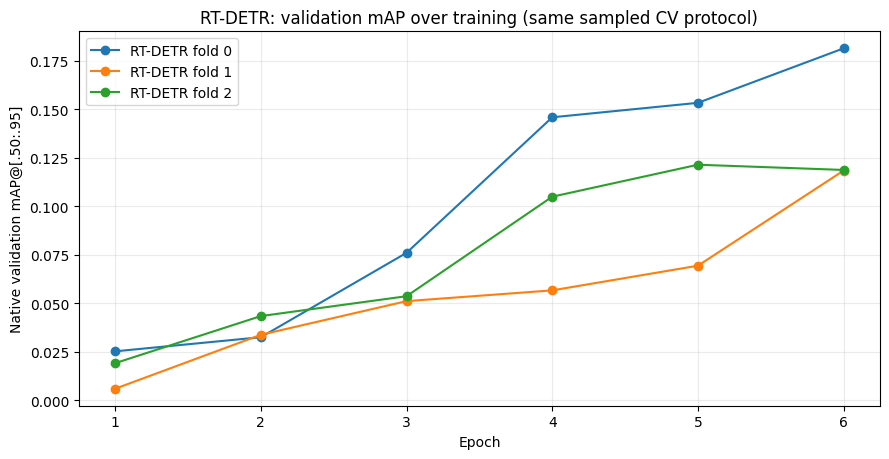

In [ ]:
fig,ax=plt.subplots(figsize=(9,4.7))
plotted=False
for fold in (0,1,2):
    csv=RUN_DIR/f'fold_{fold}'/'results.csv'
    if not csv.exists(): continue
    d=pd.read_csv(csv);d.columns=d.columns.str.strip()
    ycols=[c for c in d if 'mAP50-95' in c and '(B)' in c]
    if not ycols:
        print('No mAP column in',csv,':',list(d.columns))
        continue
    x=d['epoch'] if 'epoch' in d else np.arange(1,len(d)+1)
    ax.plot(x,d[ycols[0]],marker='o',label=f'RT-DETR fold {fold}')
    plotted=True
ax.set(xlabel='Epoch',ylabel='Native validation mAP@[.50:.95]',
       title='RT-DETR: validation mAP over training (same sampled CV protocol)')
ax.grid(alpha=.25)
if plotted:
    ax.legend();fig.tight_layout()
    fig.savefig(RUN_DIR/'rtdetr_val_map_curves.png',dpi=160)
    plt.show()
else:
    plt.close(fig);print('No completed results.csv yet')


## 6. Failure cases
Зелені boxes — GT, червоні — prediction. Перевір дрібні обʼєкти, dense scenes та неправильно локалізовані boxes. Оціни додатково кадри, де objects count > 300 (query saturation).

In [12]:
from pathlib import Path

def name_of_sequence(rec):
    return Path(
        str(rec["file_name"]).replace("\\", "/")
    ).parent.name

Small GT loaded.
Predictions processed.
Selected cases: [(74, 14567, 'uav0000279_00001_v'), (44, 14517, 'uav0000278_00001_v'), (43, 9547, 'uav0000248_00001_v')]
uav0000279_00001_v: missed small=74, TP=20, FP=22
uav0000278_00001_v: missed small=44, TP=23, FP=22
uav0000248_00001_v: missed small=43, TP=5, FP=25


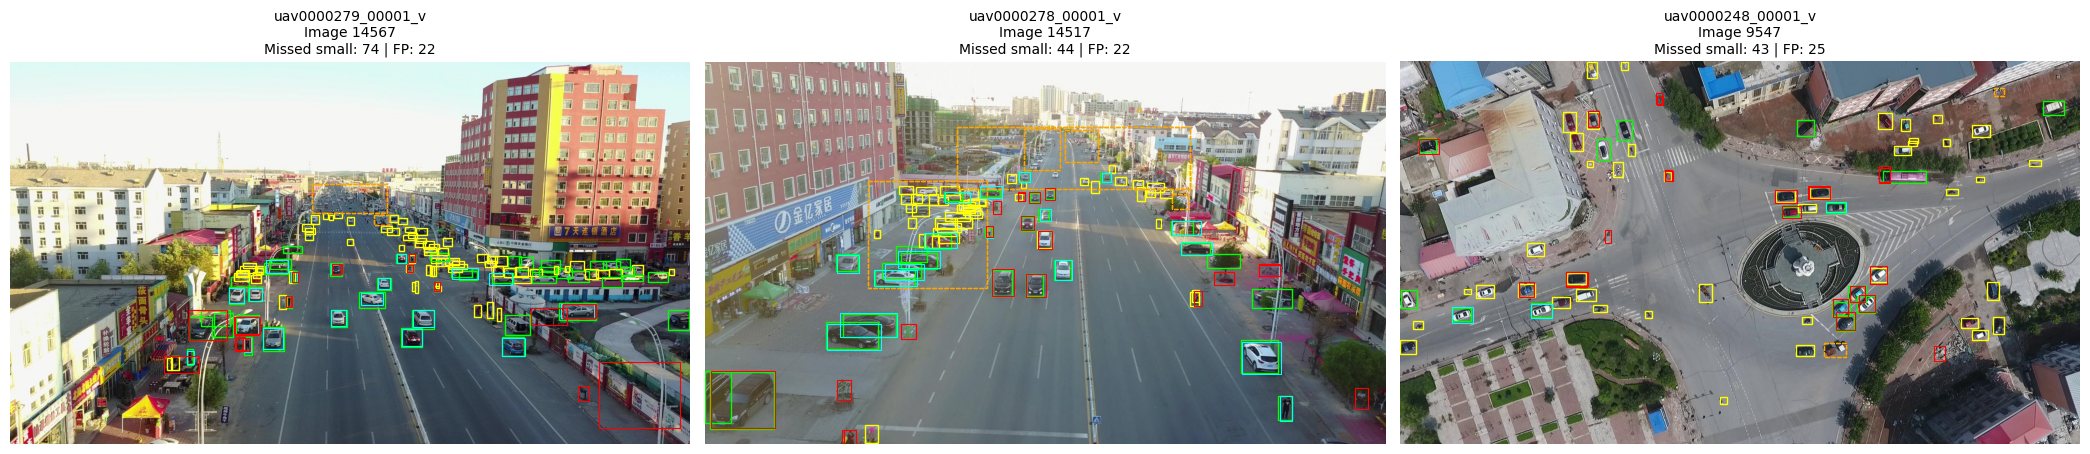


SUCCESS: failure_cases.png saved to Google Drive!
/content/drive/MyDrive/visdrone_cv/rtdetr_cv/rtdetr_denoising_50/failure_cases.png


8

In [3]:

import ijson
import gc
import shutil
from collections import defaultdict
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

SCORE_THRESHOLD = 0.25
IOU_THRESHOLD = 0.5
NUM_CASES = 3

def iou_xywh(a, b):
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / max(aw * ah + bw * bh - inter, 1e-9)

def overlaps_ignored(box, ignored):
    x, y, w, h = box
    area = max(w * h, 1e-9)
    for x1, y1, x2, y2 in ignored:
        ix = max(0, min(x + w, x2) - max(x, x1))
        iy = max(0, min(y + h, y2) - max(y, y1))
        if ix * iy / area >= 0.5:
            return True
    return False

# STEP 1: Load ONLY small GT, excluding ignored regions.
# Key: (image_id, category_id)
small = defaultdict(list)

with GT_FILE.open("rb") as f:
    for a in ijson.items(f, "annotations.item", use_float=True):
        if a.get("iscrowd", 0):
            continue
        if float(a["area"]) >= 32 * 32:
            continue

        key = (int(a["image_id"]), int(a["category_id"]))
        small[key].append([
            [float(v) for v in a["bbox"]],
            False  # matched?
        ])

print("Small GT loaded.")

# STEP 2: Stream predictions, mark matched small GT.
with PRED_FILE.open("rb") as f:
    for p in ijson.items(f, "item", use_float=True):
        if float(p["score"]) < SCORE_THRESHOLD:
            continue

        key = (int(p["image_id"]), int(p["category_id"]))

        for item in small.get(key, []):
            if not item[1] and iou_xywh(item[0], p["bbox"]) >= IOU_THRESHOLD:
                item[1] = True

print("Predictions processed.")

# STEP 3: Rank images by missed small GT.
misses_by_id = defaultdict(int)

for (image_id, category_id), objects in small.items():
    misses_by_id[image_id] += sum(
        not matched for _, matched in objects
    )

del small
gc.collect()

# Read only image names from preprocessing records.
file_names = {}

with RECORDS_FILE.open("rb") as f:
    for r in ijson.items(f, "item", use_float=True):
        ident = int(r["image_id"])
        if ident in misses_by_id:
            file_names[ident] = str(r["file_name"])

top = []
used_sequences = set()

for misses, ident in sorted(
    ((n, i) for i, n in misses_by_id.items()),
    reverse=True
):
    if misses == 0:
        break

    filename = file_names.get(ident)
    if filename is None:
        continue

    seq = Path(filename.replace("\\", "/")).parent.name

    if seq not in used_sequences:
        top.append((misses, ident, seq))
        used_sequences.add(seq)

    if len(top) == NUM_CASES:
        break

assert top, "No missed small-object cases found."

print("Selected cases:", top)

# STEP 4: Read details ONLY for selected images.
selected = {ident for _, ident, _ in top}
records = {}
gts = defaultdict(list)
preds = defaultdict(list)

with RECORDS_FILE.open("rb") as f:
    for r in ijson.items(f, "item", use_float=True):
        ident = int(r["image_id"])
        if ident in selected:
            records[ident] = r

with GT_FILE.open("rb") as f:
    for a in ijson.items(f, "annotations.item", use_float=True):
        ident = int(a["image_id"])
        if ident in selected and not a.get("iscrowd", 0):
            gts[ident].append(a)

with PRED_FILE.open("rb") as f:
    for p in ijson.items(f, "item", use_float=True):
        ident = int(p["image_id"])
        if ident in selected and float(p["score"]) >= SCORE_THRESHOLD:
            preds[ident].append(p)

# STEP 5: Plot 3 cases.
fig, axes = plt.subplots(
    1, len(top),
    figsize=(7 * len(top), 7),
    squeeze=False
)

for ax, (misses, ident, seq) in zip(axes[0], top):
    rec = records[ident]

    relative = Path(str(rec["file_name"]).replace("\\", "/"))
    img_path = DATA_ROOT / "train" / relative
    assert img_path.is_file(), f"Image not found: {img_path}"

    with Image.open(img_path) as im:
        image = im.convert("RGB").copy()

    ignored = rec.get("ignored_boxes", [])
    annotations = gts[ident]

    matched = set()
    tp, fp = [], []

    for p in sorted(preds[ident], key=lambda p: -p["score"]):
        best_idx = None
        best_iou = IOU_THRESHOLD

        for idx, a in enumerate(annotations):
            if idx in matched:
                continue
            if p["category_id"] != a["category_id"]:
                continue

            overlap = iou_xywh(p["bbox"], a["bbox"])

            if overlap >= best_iou:
                best_iou = overlap
                best_idx = idx

        if best_idx is not None:
            matched.add(best_idx)
            tp.append(p)
        elif not overlaps_ignored(p["bbox"], ignored):
            fp.append(p)

    ax.imshow(image)
    ax.axis("off")

    missed_small = 0

    for idx, a in enumerate(annotations):
        x, y, w, h = a["bbox"]

        is_missed = (
            idx not in matched
            and float(a["area"]) < 32 * 32
        )

        if is_missed:
            missed_small += 1

        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="yellow" if is_missed else "lime",
            linewidth=1
        ))

    for x1, y1, x2, y2 in ignored:
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False,
            edgecolor="orange",
            linestyle="--",
            linewidth=0.8
        ))

    for items, color in [(tp[:100], "cyan"), (fp[:100], "red")]:
        for p in items:
            x, y, w, h = p["bbox"]
            ax.add_patch(Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor=color,
                linewidth=0.8
            ))

    ax.set_title(
        f"{seq}\nImage {ident}\n"
        f"Missed small: {missed_small} | FP: {len(fp)}",
        fontsize=10
    )

    print(
        f"{seq}: missed small={missed_small}, "
        f"TP={len(tp)}, FP={len(fp)}"
    )

fig.tight_layout()

# Save locally and immediately back up to Google Drive.
LOCAL.mkdir(parents=True, exist_ok=True)
BACKUP.mkdir(parents=True, exist_ok=True)

output = LOCAL / "failure_cases.png"
fig.savefig(output, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

shutil.copy2(output, BACKUP / "failure_cases.png")

print("\nSUCCESS: failure_cases.png saved to Google Drive!")
print(BACKUP / "failure_cases.png")

gc.collect()


### Висновки

Зменшення кількості denoising queries зі 100 до 50
дало найкращий результат серед трьох експериментів. Модель досягла pooled OOF mAP@50:95 = 0.1381
порівняно з 0.1200 для baseline, що відповідає
приблизно 15.1% відносного покращення. Також зросли AP@50 з 0.2342 до 0.2662
та AP_small з 0.0272 до 0.0356. Найбільше покращення спостерігалося на fold 2,
де mAP зріс з 0.0392 до 0.1254.
Водночас на folds 0 і 1 baseline показав
дещо кращі результати.

Таким чином, denoising tuning покращив загальну
якість OOF-детекції та зменшив різницю між
результатами окремих folds. Попри покращення, малі об'єкти залишаються
найбільш складною категорією для детекції.

Отже, конфігурацію з 50 denoising queries
та learning rate = 0.001 обрали як найкращу
серед перевірених для подальшого навчання.